# widening_conversion (`widening_conversion`)

The knowledge graph around the concept `widening_conversion`, from `data/raw/chapter1_kg_updated.json`. Every edge drawn is an edge of that graph.

Cell 1 is the knowledge graph visualizer (the same code as `notebooks/kg_visualizer.ipynb`). Cell 2 draws the view of `widening_conversion` and writes `widening_conversion.html` (interactive graph), `widening_conversion.json` (nodes and edges) and `widening_conversion.png` (still picture) next to this notebook.

In [1]:
# ===== CPAL Chapter 1 — Knowledge Graph Visualizer v3.9.x (single cell) =====
# Works with data/raw/chapter1_kg_updated.json (v3.9.x): sections, topics, concepts,
# learning_levels, misconceptions_and_errors, edges.
# Local Jupyter version of the Colab cell: the graph is read from the repository, files are read as UTF-8.
# Needs pyvis 0.3.2 (pip install pyvis==0.3.2) and ipywidgets.

import json, glob, os, base64, html as _html
from pathlib import Path
import networkx as nx
from pyvis.network import Network
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
try:
    from google.colab import output as _co
    _co.enable_custom_widget_manager()
except Exception:
    pass

# ---------- load ----------
ROOT = Path.cwd().resolve()
while not (ROOT / 'data' / 'raw').exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
JSON_PATH = str(ROOT / 'data' / 'raw' / 'chapter1_kg_updated.json')   # change to use another graph file
if not os.path.exists(JSON_PATH):
    hits = (sorted(glob.glob(str(ROOT / 'data' / '**' / '*kg*.json'), recursive=True), reverse=True)
            or glob.glob(str(ROOT / '**' / '*kg*.json'), recursive=True))
    if not hits:
        raise FileNotFoundError("No knowledge graph JSON found under data/raw.")
    JSON_PATH = hits[0]
DATA = json.load(open(JSON_PATH, encoding='utf-8'))
for k in ('sections', 'topics', 'concepts', 'learning_levels', 'misconceptions_and_errors', 'edges'):
    if k not in DATA:
        raise KeyError(f"'{k}' missing: this cell needs the v3.9.x knowledge graph JSON.")

# Reader blocks (the code patterns that tag a concept from the code). If this file has none,
# another JSON with reader blocks under data/ is used for them.
READER, READER_FILE = {c['id']: c['reader'] for c in DATA['concepts'] if c.get('reader')}, JSON_PATH
if not READER:
    READER_FILE = None
    for _p in glob.glob(str(ROOT / 'data' / '**' / '*.json'), recursive=True):
        if os.path.abspath(_p) == os.path.abspath(JSON_PATH):
            continue
        try:
            _d = json.load(open(_p, encoding='utf-8'))
            _r = {c['id']: c['reader'] for c in (_d.get('concepts', []) if isinstance(_d, dict) else [])
                  if isinstance(c, dict) and c.get('reader')}
        except Exception:
            continue
        if _r:
            READER, READER_FILE = _r, _p
            break

def _esc(s):  return _html.escape(str(s or ''))
def _trim(s, n=70):
    s = str(s or '')
    return s if len(s) <= n else s[:n - 1] + '…'

# The 13 rule types stored on every concept (rules_by_type) and on every level way (rule_type).
RULE_TYPE_NAMES = {'E': 'folk-meaning rule', 'S': 'declarative rule', 'N': 'identity rule',
                   'LT': 'operational sequencing rule', 'OP': 'evaluation / result rule',
                   'OS': 'state-transition rule', 'C': 'conservation rule', 'T': 'uneven-application rule',
                   'P': 'plan / role rule', 'X': 'applicability rule', 'M': 'wrong rule / right rule',
                   'R': 'composition rule (with a neighbour)', 'D': 'error rule'}

def concept_rules(c):
    """Every rule stated on a concept node: (rule type, text), from rules_by_type."""
    out = []
    for t, v in (c.get('rules_by_type') or {}).items():
        if isinstance(v, dict):
            if v.get('rule'):
                out.append((t, v['rule']))
        elif t == 'M':
            out += [(t, f"{it.get('node')}: wrong: {it.get('wrong')} | right: {it.get('right')}") for it in v]
        elif t == 'R':
            out += [(t, f"with {it.get('neighbour')}: {it.get('rule')}") for it in v]
        elif t == 'D':
            out += [(t, f"rule broken: {it.get('rule_broken') or it.get('rule')}"
                        + (f" ({it.get('kind')})" if it.get('kind') else '')) for it in v]
    return out

def ways_text(e, sep='\n'):
    """Every way of a has_level edge with its exact rule."""
    return sep.join(f"[{i}] {w.get('way')} ({w.get('rule_type')})"
                    + (f" -> {', '.join(w.get('linked_misconception') or [])}" if w.get('linked_misconception') else '')
                    + f": {w.get('exact_rule', '')}" for i, w in enumerate(e.get('ways') or []))

# ---------- build ----------
def build_graph(data):
    G = nx.MultiDiGraph()
    for s in data['sections']:
        G.add_node(s['id'], layer='section', label=s.get('label', s['id']), section=str(s.get('section', s['id'])),
                   title=f"<b>{_esc(s.get('label'))}</b><br>Section {_esc(s.get('section', s['id']))}")
    for t in data['topics']:
        G.add_node(t['id'], layer='topic', label=t.get('label', t['id']), section=t.get('section', ''),
                   title=f"<b>{_esc(t.get('label'))}</b><br>{_esc(t.get('book_quote',''))[:400]}")
    sec_of = {}
    for c in data['concepts']:
        sec_of[c['id']] = c.get('section', '')
        rules = concept_rules(c)
        G.add_node(c['id'], layer='concept', label=c.get('label', c['id']), section=c.get('section', ''),
                   rules=rules,
                   title=f"<b>{_esc(c.get('label'))}</b> <i>({c['id']}, §{_esc(c.get('section'))})</i>"
                         f"<br>{_esc(c.get('description',''))}"
                         + ''.join(f"<br><i>book:</i> “{_esc(q.get('quote'))}”" for q in (c.get('rules') or [])[:2])
                         + ''.join(f"<br><b>{_esc(t)}</b> ({_esc(RULE_TYPE_NAMES.get(t, t))}): {_esc(r)}" for t, r in rules))
    for l in data['learning_levels']:
        G.add_node(l['id'], layer='learning_level', label=l['level'], concept=l['concept'],
                   section=sec_of.get(l['concept'], ''),
                   title=f"<b>{_esc(l['concept'])} @ {l['level']} — {_esc(l.get('name',''))}</b>"
                         f"<br>{_esc(l.get('criterion',''))}<br><i>{_esc(l.get('deciding_question',''))}</i>")
    for m in data['misconceptions_and_errors']:
        lay = 'error' if (m.get('kind') or m.get('type')) == 'error' else 'misconception'
        G.add_node(m['id'], layer=lay, label=m.get('label', m['id']), section='',
                   title=f"<b>{_esc(m['id'])}</b> ({lay})<br><b>wrong:</b> {_esc(m.get('wrong_belief',''))}"
                         f"<br><b>right:</b> {_esc(m.get('correct_rule',''))}"
                         f"<br><i>provenance: {_esc(m.get('provenance',''))}</i>")
    for e in data['edges']:
        s, t, et = e.get('source'), e.get('target'), e.get('type', '?')
        if s not in G or t not in G:
            continue
        logic = e.get('logic') or e.get('edge_logic') or ''
        if et in ('misconception', 'error') and e.get('twin_logic'):
            logic = f"wrong: {logic} | right: {e['twin_logic']}"          # both rules are stated on the edge
        elif et == 'has_level' and e.get('ways'):
            logic = ways_text(e)                                          # every way with its exact rule
        ttl = f"<b>{et}</b>: {_esc(s)} → {_esc(t)}<br>{_esc(logic)}"
        if e.get('twin_logic'):
            ttl += f"<br><b>correct:</b> {_esc(e['twin_logic'])}"
        if e.get('role'):
            ttl += f"<br><i>role: {e['role']}</i>"
        if e.get('grounding'):
            ttl += f"<br><i>grounding: {e['grounding']}</i>"
        if et == 'has_level' and e.get('ways'):
            ttl = (f"<b>{et}</b>: {_esc(s)} → {_esc(t)}<br>{_esc(e.get('logic', ''))}<br>" + '<br>'.join(
                f"• <b>[{i}] {_esc(w.get('way'))}</b> ({_esc(w.get('rule_type'))})"
                + (f" → <i>{_esc(', '.join(w.get('linked_misconception') or []))}</i>" if w.get('linked_misconception') else '')
                + f": {_esc(w.get('exact_rule',''))}" for i, w in enumerate(e['ways'])))
        G.add_edge(s, t, etype=et, etitle=ttl, elogic=logic)
    return G

G = build_graph(DATA)
ALL_LAYERS = ['section', 'topic', 'concept', 'learning_level', 'misconception', 'error']
ALL_ETYPES = ['contains', 'precedes', 'section_prerequisite', 'prerequisite', 'parallel',
              'has_level', 'misconception', 'error']
SECTIONS   = [str(s.get('section', s['id'])) for s in DATA['sections']]
CONCEPTS   = sorted(c['id'] for c in DATA['concepts'])
_loaded = (f"Loaded {JSON_PATH} | version {_trim(DATA.get('version'), 60)} | "
           f"nodes {G.number_of_nodes()} | edges {G.number_of_edges()}")

ARROW = ' → '
_LEVEL_NODE = {l['id']: l for l in DATA['learning_levels']}
LEVEL_COLOR = {'L0': '#C62828', 'L1': '#EF6C00', 'L2': '#F9A825', 'L3': '#2E7D32', 'L4': '#1B5E20'}
_HAS_LEVEL = {(e['source'], e['level']): e for e in DATA['edges'] if e['type'] == 'has_level'}
_MIS_EDGE = {(e['source'], e['target']): e for e in DATA['edges'] if e['type'] in ('misconception', 'error')}
_REL_EDGE = {}
for e in DATA['edges']:
    if e['type'] in ('prerequisite', 'parallel'):
        _REL_EDGE[frozenset((e['source'], e['target']))] = e
_CONCEPT = {c['id']: c for c in DATA['concepts']}
_MISNODE = {m['id']: m for m in DATA['misconceptions_and_errors']}
_REL = nx.Graph()
for e in _REL_EDGE.values():
    _REL.add_edge(e['source'], e['target'])

def edge_id(e):
    return f"pre:{e['source']}->{e['target']}" if e['type'] == 'prerequisite' else f"par:{e['source']}~{e['target']}"

# ======================================================================
# Concept view: everything in the KG that is related to one concept,
# and what is still missing for it ("to work on").
# ======================================================================
LEVELS = ('L0', 'L1', 'L2', 'L3', 'L4')
_PRE = nx.DiGraph()
for e in DATA['edges']:
    if e.get('type') == 'prerequisite':
        _PRE.add_edge(e['source'], e['target'])

def concept_related(c):
    r = dict(topics=[], needs=[], unlocks=[], parallel=[], mis=[], err=[], levels={})
    for e in DATA['edges']:
        s, t, et = e.get('source'), e.get('target'), e.get('type')
        if c not in (s, t):
            continue
        if et == 'contains' and t == c:
            r['topics'].append(s)
        elif et == 'prerequisite':
            (r['needs'] if t == c else r['unlocks']).append(e)
        elif et == 'parallel':
            r['parallel'].append(e)
        elif et == 'misconception' and s == c:
            r['mis'].append(e)
        elif et == 'error' and s == c:
            r['err'].append(e)
        elif et == 'has_level' and s == c:
            r['levels'][e.get('level') or str(t).split('@')[-1]] = e
    r['all_needs'] = sorted(nx.ancestors(_PRE, c)) if c in _PRE else []
    r['all_unlocks'] = sorted(nx.descendants(_PRE, c)) if c in _PRE else []
    l0 = r['levels'].get('L0', {})
    r['l0_linked'] = {m for w in l0.get('ways', []) for m in (w.get('linked_misconception') or [])}
    return r

def concept_gaps(c, r=None):
    """What is missing in the KG for this concept: the list of things to work on."""
    r = r or concept_related(c)
    gaps = []
    miss = [L for L in LEVELS if L not in r['levels']]
    if miss:
        gaps.append('no level node for ' + ', '.join(miss))
    for L in LEVELS:
        if L in r['levels'] and not r['levels'][L].get('ways'):
            gaps.append(f'{L} has no ways')
    if not (r['needs'] or r['unlocks'] or r['parallel']):
        gaps.append('no prerequisite or parallel edge: the concept is isolated')
    for e in r['needs'] + r['unlocks'] + r['parallel']:
        if not (e.get('logic') or e.get('edge_logic')):
            gaps.append(f"edge {e['source']} - {e['target']} has no edge logic")
    if not (r['mis'] or r['err']):
        gaps.append('no misconception or error edge')
    for e in r['mis'] + r['err']:
        if not e.get('logic'):
            gaps.append(f"{e['target']}: no wrong-rule logic")
        if not e.get('twin_logic'):
            gaps.append(f"{e['target']}: no twin (correct) logic")
    nolink = [e['target'] for e in r['mis'] if e['target'] not in r['l0_linked']]
    if nolink:
        gaps.append('misconceptions with no L0 way linked to them: ' + ', '.join(nolink))
    if READER:
        rd = READER.get(c) or {}
        if not (rd.get('code_patterns') or rd.get('signals') or rd.get('operator_symbols') or rd.get('java_types')):
            gaps.append('no code pattern or signal: the code cannot tag this concept')
        if not rd.get('aliases'):
            gaps.append('no aliases: a student\'s words cannot name this concept')
    return gaps

def _ways_html(e):
    items = []
    for i, w in enumerate(e.get('ways', [])):
        link = w.get('linked_misconception')
        items.append(f"<li><b>[{i}] {_esc(w.get('way'))}</b> ({_esc(w.get('rule_type'))})"
                     f"{' → <i>' + _esc(', '.join(link)) + '</i>' if link else ''}: {_esc(w.get('exact_rule', ''))}</li>")
    return '<ul style="margin:2px 0;padding-left:18px">' + ''.join(items) + '</ul>' if items else '<i>no ways</i>'

def concept_report(c):
    d = _CONCEPT.get(c, {})
    r = concept_related(c)
    gaps = concept_gaps(c, r)
    T = "style='border-collapse:collapse;width:100%;margin:4px 0' border='1' cellpadding='4'"
    H = "style='background:#f2f2f2'"
    h4 = lambda t: f"<h4 style='margin:12px 0 2px 0'>{t}</h4>"
    out = ["<div style='background:#fff;color:#111;padding:10px;border:1px solid #ddd;border-radius:6px;"
           "margin-bottom:6px;font-family:arial;font-size:13px'>"]
    out.append(f"<h3 style='margin:0 0 4px 0'>{_esc(d.get('label', c))} <span style='font-size:13px;color:#555'>"
               f"(id <code>{_esc(c)}</code>, section {_esc(d.get('section'))} {_esc(d.get('section_title', ''))}, "
               f"topic {_esc(d.get('topic'))} {_esc(d.get('topic_title', ''))})</span></h3>"
               f"<b>Description:</b> {_esc(d.get('description', ''))}")
    if r['topics']:
        out.append(f"<br><b>Contained in topic:</b> {_esc(', '.join(r['topics']))}")
    n_rel = len(r['needs']) + len(r['unlocks']) + len(r['parallel'])
    out.append(f"<br><b>Summary:</b> {len(r['needs'])} prerequisites, {len(r['unlocks'])} concepts it leads to, "
               f"{len(r['parallel'])} parallel, {len(r['levels'])} of 5 level nodes, "
               f"{sum(len(e.get('ways', [])) for e in r['levels'].values())} level ways, "
               f"{len(r['mis'])} misconceptions, {len(r['err'])} errors")
    # what to work on
    col = '#1B5E20' if not gaps else '#C62828'
    out.append(h4(f"<span style='color:{col}'>To work on ({len(gaps)})</span>"))
    out.append("<b style='color:#1B5E20'>Nothing missing for this concept.</b>" if not gaps else
               '<ul style="margin:2px 0">' + ''.join(f'<li>{_esc(g)}</li>' for g in gaps) + '</ul>')
    # the concept's own rules
    out.append(h4(f"Rules of the concept ({len(G.nodes[c].get('rules', [])) if c in G else 0})"))
    for q in d.get('rules') or []:
        out.append(f"<div>Book ({_esc(q.get('source'))}, {_esc(q.get('locator') or q.get('pdf_page'))}): "
                   f"<i>“{_esc(q.get('quote'))}”</i></div>")
    out.append(f"<table {T}><tr {H}><th>Rule type</th><th>Rule</th></tr>"
               + ''.join(f"<tr><td><b>{_esc(t)}</b> {_esc(RULE_TYPE_NAMES.get(t, t))}</td><td>{_esc(r)}</td></tr>"
                         for t, r in (G.nodes[c].get('rules', []) if c in G else []))
               + "</table>")
    # reader
    out.append(h4('How it is found in code and answers (reader block)'))
    if not READER:
        out.append("<i>This graph file has no reader blocks. Put a graph file with reader blocks under data/ "
                   "and re-run the cell to see the code patterns.</i>")
    else:
        rd = READER.get(c) or {}
        out.append(f"<i>from {_esc(os.path.basename(READER_FILE or ''))}</i><ul style='margin:2px 0'>"
                   f"<li><b>aliases:</b> {_esc(', '.join(rd.get('aliases', [])) or 'none')}</li>"
                   f"<li><b>code patterns:</b> {_esc(' | '.join(rd.get('code_patterns', [])) or 'none')}</li>"
                   f"<li><b>operator symbols:</b> {_esc(', '.join(rd.get('operator_symbols', [])) or 'none')}</li>"
                   f"<li><b>java types:</b> {_esc(', '.join(rd.get('java_types', [])) or 'none')}</li>"
                   + ''.join(f"<li><b>signal {_esc(s.get('name'))}</b> (scope {_esc(s.get('scope'))}"
                             f"{', decisive' if s.get('decisive') else ''}): <code>{_esc(s.get('regex'))}</code></li>"
                             for s in rd.get('signals', []))
                   + "</ul>")
    # relation edges
    def rel_table(title, edges, other_end):
        if not edges:
            out.append(h4(title) + '<i>none</i>')
            return
        out.append(h4(f'{title} ({len(edges)})') +
                   f"<table {T}><tr {H}><th>Concept</th><th>Edge</th><th>Edge logic (from the KG)</th><th>Grounding</th></tr>")
        for e in edges:
            o = other_end(e)
            out.append(f"<tr><td><b>{_esc(o)}</b><br><span style='color:#555'>{_esc(_CONCEPT.get(o, {}).get('description', ''))}</span></td>"
                       f"<td><code>{_esc(edge_id(e))}</code></td><td>{_esc(e.get('logic') or e.get('edge_logic', ''))}</td>"
                       f"<td>{_esc(e.get('grounding', ''))}</td></tr>")
        out.append('</table>')
    rel_table('Needs (prerequisites)', r['needs'], lambda e: e['source'])
    rel_table('Leads to (concepts that need it)', r['unlocks'], lambda e: e['target'])
    rel_table('Parallel concepts', r['parallel'], lambda e: e['target'] if e['source'] == c else e['source'])
    out.append(h4('Full prerequisite chain') +
               f"<b>everything it builds on ({len(r['all_needs'])}):</b> {_esc(', '.join(r['all_needs'])) or 'none'}<br>"
               f"<b>everything that builds on it ({len(r['all_unlocks'])}):</b> {_esc(', '.join(r['all_unlocks'])) or 'none'}")
    # levels
    out.append(h4('Levels L0 to L4 and their ways') +
               f"<table {T}><tr {H}><th>Level</th><th>Name and criterion</th><th>Ways (way, rule type → linked misconception: exact rule)</th></tr>")
    for L in LEVELS:
        ln = _LEVEL_NODE.get(f'{c}@{L}')
        e = r['levels'].get(L)
        out.append(f"<tr><td style='color:#fff;background:{LEVEL_COLOR[L]};text-align:center'><b>{L}</b></td>"
                   + (f"<td><b>{_esc(ln.get('name', ''))}</b><br>{_esc(ln.get('criterion', ''))}"
                      f"<br><i>{_esc(ln.get('deciding_question', ''))}</i></td>" if ln else
                      "<td><b style='color:#C62828'>level node missing</b></td>")
                   + f"<td>{_ways_html(e) if e else '<b style=color:#C62828>no has_level edge</b>'}</td></tr>")
    out.append('</table>')
    # misconceptions and errors
    for title, edges in (('Misconceptions', r['mis']), ('Errors', r['err'])):
        if not edges:
            out.append(h4(title) + '<i>none</i>')
            continue
        out.append(h4(f'{title} ({len(edges)})') +
                   f"<table {T}><tr {H}><th>Id</th><th>Role</th><th>Wrong logic</th><th>Correct (twin) logic</th><th>L0 way linked?</th></tr>")
        for e in edges:
            ok = e['target'] in r['l0_linked']
            out.append(f"<tr><td><b>{_esc(e['target'])}</b></td><td>{_esc(e.get('role', ''))}</td>"
                       f"<td>{_esc(e.get('logic', ''))}</td><td>{_esc(e.get('twin_logic', ''))}</td>"
                       f"<td style='color:{'#1B5E20' if ok else '#C62828'}'><b>{'yes' if ok else 'no'}</b></td></tr>")
        out.append('</table>')
    out.append('</div>')
    return ''.join(out)

def all_concepts_report():
    rows, n_gap = [], 0
    for c in CONCEPTS:
        r = concept_related(c)
        gaps = concept_gaps(c, r)
        n_gap += bool(gaps)
        rd = READER.get(c) or {}
        tag = ('-' if not READER else
               'yes' if (rd.get('code_patterns') or rd.get('signals') or rd.get('operator_symbols') or rd.get('java_types')) else 'no')
        rows.append(f"<tr><td><b>{_esc(c)}</b></td><td>{_esc(_CONCEPT[c].get('section'))}</td>"
                    f"<td>{len(r['needs'])}</td><td>{len(r['unlocks'])}</td><td>{len(r['parallel'])}</td>"
                    f"<td>{len(r['levels'])}/5</td><td>{sum(len(e.get('ways', [])) for e in r['levels'].values())}</td>"
                    f"<td>{len(r['mis'])}</td><td>{len(r['err'])}</td><td>{tag}</td>"
                    f"<td style='color:{'#1B5E20' if not gaps else '#C62828'}'>{_esc('; '.join(gaps)) or 'nothing missing'}</td></tr>")
    note = '' if READER else ' (no reader blocks loaded, so code tagging is not checked)'
    return (f"<div style='background:#fff;color:#111;padding:10px;font-family:arial;font-size:13px'>"
            f"<h3 style='margin:0'>All {len(CONCEPTS)} concepts: {n_gap} have something to work on{note}</h3>"
            f"<table style='border-collapse:collapse;width:100%' border='1' cellpadding='4'><tr style='background:#f2f2f2'>"
            f"<th>Concept</th><th>Sec.</th><th>Needs</th><th>Leads to</th><th>Parallel</th><th>Levels</th><th>Ways</th>"
            f"<th>Misc.</th><th>Errors</th><th>Code tag</th><th>To work on</th></tr>"
            + ''.join(rows) + "</table></div>")

_MIS_OWNERS = {}                     # misconception / error -> concepts that have an edge to it
for e in DATA['edges']:
    if e.get('type') in ('misconception', 'error'):
        _MIS_OWNERS.setdefault(e['target'], set()).add(e['source'])
_TOPIC_KIDS = {}                     # topic -> concepts it contains
for e in DATA['edges']:
    if e.get('type') == 'contains' and e['target'] in _CONCEPT:
        _TOPIC_KIDS.setdefault(e['source'], set()).add(e['target'])
_R_RULE = {}                         # (concept, neighbour) -> composition rule (rule type R)
for _c in DATA['concepts']:
    for it in (_c.get('rules_by_type') or {}).get('R') or []:
        if isinstance(it, dict) and it.get('neighbour'):
            _R_RULE[(_c['id'], it['neighbour'])] = it.get('rule', '')

def concept_associations(c, hops=1):
    """Every concept associated with c, and how: {concept: [reasons]}."""
    assoc = {}
    def add(o, why):
        if o != c and o in _CONCEPT:
            assoc.setdefault(o, [])
            if why not in assoc[o]:
                assoc[o].append(why)
    for e in DATA['edges']:
        s_, t_, et = e.get('source'), e.get('target'), e.get('type')
        if et == 'prerequisite' and t_ == c:
            add(s_, 'prerequisite of it (it needs this)')
        elif et == 'prerequisite' and s_ == c:
            add(t_, 'builds on it (needs it)')
        elif et == 'parallel' and c in (s_, t_):
            add(t_ if s_ == c else s_, 'parallel concept')
    for (a, b), _ in _R_RULE.items():
        if a == c:
            add(b, 'composition rule (R) with it')
        elif b == c:
            add(a, 'composition rule (R) with it')
    if hops > 1 and c in _REL:                       # further out over prerequisite / parallel edges
        dist = nx.single_source_shortest_path_length(_REL, c, cutoff=hops)
        for o, k in dist.items():
            if k > 1:
                add(o, f'{k} steps away over prerequisite / parallel edges')
    for m, owners in _MIS_OWNERS.items():           # concepts that share a misconception or error
        if c in owners:
            for o in owners:
                add(o, f"shares {G.nodes[m]['layer'] if m in G else 'misconception'} {m}")
    for t, kids in _TOPIC_KIDS.items():              # concepts in the same topic
        if c in kids:
            for o in kids:
                add(o, f'same topic ({t})')
    return assoc

def concept_nodes(c, layers, hops):
    """The concept, every concept associated with it (prerequisite, parallel, composition rule,
    shared misconception / error, same topic), its topic, its level nodes and its misconceptions / errors."""
    r = concept_related(c)
    keep = {c}
    if 'concept' in layers:
        keep |= {o for o in concept_associations(c, hops) if o in G}
    keep |= {t for t in r['topics'] if t in G and 'topic' in layers}
    if 'learning_level' in layers:
        keep |= {f'{c}@{L}' for L in LEVELS if f'{c}@{L}' in G}
    keep |= {e['target'] for e in r['mis'] + r['err'] if e['target'] in G and G.nodes[e['target']]['layer'] in layers}
    return keep

def _full_label_html(u, v, et):
    """The full edge label, written out (used in the write-up under the graph)."""
    if et == 'has_level':
        e = _HAS_LEVEL.get((u, str(v).split('@')[-1]), {})
        return f"{_esc(e.get('logic', ''))}{_ways_html(e)}"
    if et in ('misconception', 'error'):
        e = _MIS_EDGE.get((u, v), {})
        return (f"<b style='color:#C62828'>wrong rule:</b> {_esc(e.get('logic', ''))}<br>"
                f"<b style='color:#1B5E20'>right rule:</b> {_esc(e.get('twin_logic', ''))}"
                + (f"<br><i>role: {_esc(e.get('role'))}</i>" if e.get('role') else ''))
    if et in ('prerequisite', 'parallel'):
        e = _REL_EDGE.get(frozenset((u, v)), {})
        out = f"{_esc(e.get('logic') or e.get('edge_logic', ''))}"
        if e.get('grounding'):
            out += f"<br><i>grounding: {_esc(e['grounding'])}</i>"
        for a, b in ((u, v), (v, u)):
            if (a, b) in _R_RULE:
                out += f"<br><b>composition rule (R) of {_esc(a)} with {_esc(b)}:</b> {_esc(_R_RULE[(a, b)])}"
        return out
    if et == 'contains':
        return f"topic {_esc(u)} contains {_esc(v)}"
    return ''

def edges_writeup(H, c='None'):
    """Write-up of every edge in the view with its full label, and how each concept is associated."""
    T = "style='border-collapse:collapse;width:100%;margin:4px 0' border='1' cellpadding='4'"
    Hd = "style='background:#f2f2f2'"
    out = ["<div style='background:#fff;color:#111;padding:10px;border:1px solid #ddd;border-radius:6px;"
           "margin-top:8px;font-family:arial;font-size:13px'>"]
    if c != 'None':
        assoc = concept_associations(c, hops_sl.value)
        shown = {o: w for o, w in assoc.items() if o in H}
        out.append(f"<h3 style='margin:0 0 4px 0'>Other concepts in the view of {_esc(c)} ({len(shown)})</h3>"
                   f"<table {T}><tr {Hd}><th>Concept</th><th>Description</th><th>How the knowledge graph links it</th></tr>"
                   + ''.join(f"<tr><td><b>{_esc(o)}</b></td><td>{_esc(_CONCEPT[o].get('description', ''))}</td>"
                             f"<td>{'<br>'.join(_esc(x) for x in w)}</td></tr>" for o, w in sorted(shown.items()))
                   + "</table>")
    order = ['prerequisite', 'parallel', 'misconception', 'error',
             'has_level', 'contains',
             'precedes', 'section_prerequisite']
    edges = sorted(((u, v, d['etype']) for u, v, d in H.edges(data=True)),
                   key=lambda x: (order.index(x[2]) if x[2] in order else 99, x[0], str(x[1])))
    out.append(f"<h3 style='margin:12px 0 4px 0'>Every edge in this view and its full label ({len(edges)})</h3>"
               f"<table {T}><tr {Hd}><th>From</th><th>Edge</th><th>To</th><th>Full edge label</th></tr>")
    for u, v, et in edges:
        out.append(f"<tr><td><b>{_esc(u)}</b></td><td>{_esc(et)}</td><td><b>{_esc(v)}</b></td>"
                   f"<td>{_full_label_html(u, v, et)}</td></tr>")
    out.append("</table></div>")
    return ''.join(out)

# ---------- styles ----------
LAYER_STYLE = {
    'section':        {'color': '#E8A33D', 'shape': 'box',      'size': 30, 'font': 18},
    'topic':          {'color': '#F2C879', 'shape': 'box',      'size': 22, 'font': 14},
    'concept':        {'color': '#3B7DE0', 'shape': 'dot',      'size': 18, 'font': 16},
    'learning_level': {'color': '#1FA463', 'shape': 'diamond',  'size': 11, 'font': 12},
    'misconception':  {'color': '#D63B30', 'shape': 'triangle', 'size': 15, 'font': 13},
    'error':          {'color': '#8E44AD', 'shape': 'star',     'size': 15, 'font': 13},
}
EDGE_STYLE = {
    'contains':             {'color': '#9E9E9E', 'width': 1.5, 'dashes': False},
    'precedes':             {'color': '#E65100', 'width': 3,   'dashes': False},
    'section_prerequisite': {'color': '#E65100', 'width': 2,   'dashes': True},
    'prerequisite':         {'color': '#2E7D32', 'width': 2.5, 'dashes': False},
    'parallel':             {'color': '#616161', 'width': 2,   'dashes': True},
    'has_level':            {'color': '#1E88E5', 'width': 1.2, 'dashes': True},
    'misconception':        {'color': '#C62828', 'width': 2,   'dashes': False},
    'error':                {'color': '#8E44AD', 'width': 2,   'dashes': False},
}
LOGIC_ON_EDGE = {'prerequisite', 'parallel', 'misconception', 'error', 'has_level', 'contains'}

def _node_font(sz):
    return {'color': '#111111', 'size': sz, 'face': 'arial',
            'strokeWidth': 4, 'strokeColor': '#ffffff', 'bold': True}

# ---------- filter ----------
def filter_graph(layers, etypes, section, focus, hops, hide_iso, concept='None'):
    msg = ''
    if concept != 'None':
        keep = concept_nodes(concept, layers, hops)
    else:
        keep = {n for n, d in G.nodes(data=True) if d['layer'] in layers}
        if section != 'All' and not (focus and focus in G):   # a Focus concept takes priority over Section
            sec = {n for n in keep if G.nodes[n].get('section') == section}
            cs = {n for n in sec if G.nodes[n]['layer'] == 'concept'}
            for n in keep:   # misconceptions / errors attached to this section's concepts
                if G.nodes[n]['layer'] in ('misconception', 'error') and set(G.predecessors(n)) & cs:
                    sec.add(n)
            keep = sec
        if focus and focus in G:
            ball = set(nx.ego_graph(G.to_undirected(as_view=True), focus, radius=hops).nodes)
            keep = (keep & ball) | {focus}
    H = nx.MultiDiGraph()
    for n in keep:
        H.add_node(n, **G.nodes[n])
    seen = set()
    center = concept if concept != 'None' else (focus if focus and focus in G else None)
    dist = (nx.single_source_shortest_path_length(_REL, center, cutoff=hops)
            if center and center in _REL else {})
    for u, v, d in G.edges(data=True):
        if u in keep and v in keep and d['etype'] in etypes and (u, v, d['etype']) not in seen:
            if center and center not in (u, v):
                # every edge drawn is an edge of the knowledge graph. Between two other concepts, a
                # prerequisite / parallel edge is drawn only when it leads one step further out (Hops > 1).
                if d['etype'] in ('prerequisite', 'parallel') and dist.get(u, -1) == dist.get(v, -2):
                    continue
                if d['etype'] in ('prerequisite', 'parallel') and (u not in dist or v not in dist):
                    continue
            if center and d['etype'] == 'has_level' and u != center:
                continue                 # only the chosen concept's own levels
            # 'contains' (the concept's topic -> the other concepts of that topic) and 'misconception' /
            # 'error' (another concept -> a misconception it shares with the chosen one) are graph edges:
            # they are drawn as they are, so a shared misconception shows as two real edges into one node.
            seen.add((u, v, d['etype']))
            H.add_edge(u, v, **d)
    if hide_iso:
        protect = {focus, concept}
        H.remove_nodes_from([n for n in list(H.nodes()) if H.degree(n) == 0 and n not in protect])
    return H, msg

def _wrap(text, n=38):
    words, lines, cur = str(text or '').split(), [], ''
    for w in words:
        if cur and len(cur) + 1 + len(w) > n:
            lines.append(cur); cur = w
        else:
            cur = (cur + ' ' + w).strip()
    if cur: lines.append(cur)
    return '\n'.join(lines)

import math

def radial_layout(H, center):
    """Fixed, uncrowded positions around one concept:
    associated concepts in an arc above, misconceptions / errors in an arc below,
    the level nodes in a column on the left, topics / sections on the right.
    Neighbouring nodes in an arc alternate between two radii so their labels do not touch."""
    groups = {'concept': [], 'mis': [], 'level': [], 'other': []}
    for n, d in H.nodes(data=True):
        if n == center:
            continue
        lay = d['layer']
        groups['concept' if lay == 'concept' else 'mis' if lay in ('misconception', 'error')
               else 'level' if lay == 'learning_level' else 'other'].append(n)
    pos = {center: (0, 0)}
    def arc(nodes, a0, a1, rmin, gap=190):
        if not nodes:
            return
        span = math.radians(a1 - a0)
        r = max(rmin, len(nodes) * gap / span / 2)          # two staggered rows
        for i, n in enumerate(nodes):
            a = math.radians(a0) + span * (i + 0.5) / len(nodes)
            rr = r + (170 if i % 2 else 0)
            pos[n] = (rr * math.cos(a), rr * math.sin(a))
        return r
    # concepts above (sorted by name); misconceptions below, grouped next to the concepts that share them
    # concepts one step away on the inner arc; concepts further out (Hops > 1) on outer arcs,
    # each next to the concept it is reached through
    CH = H.subgraph([center] + groups['concept']).to_undirected(as_view=True)
    dist = nx.single_source_shortest_path_length(CH, center) if center in CH else {}
    rings = {}
    for n in groups['concept']:
        rings.setdefault(dist.get(n, 1), []).append(n)
    rc, rmin = 520, 520
    for k in sorted(rings):
        def ang(n):
            ps = [pos[u] for u in CH.neighbors(n) if u in pos and u != center and dist.get(u, 0) < k]
            return (sum(math.atan2(y, x) for x, y in ps) / len(ps)) if ps else 0
        ring = sorted(rings[k]) if k == 1 else sorted(rings[k], key=lambda n: (ang(n), n))
        rc = arc(ring, -150, -30, rmin) or rmin
        rmin = rc + 170 + 380
    def owner_x(m):
        xs = [pos[u][0] for u in H.predecessors(m) if u in pos and u != center]
        return (sum(xs) / len(xs)) if xs else 0
    mis = sorted(groups['mis'], key=lambda m: (owner_x(m), m))
    rm = arc(mis, 30, 150, 620) or 620
    side = max(rc, rm) + 170
    levels = sorted(groups['level'], key=lambda n: str(n).split('@')[-1])
    for i, n in enumerate(levels):                           # L0 at the top of the column
        pos[n] = (-side, (i - (len(levels) - 1) / 2) * 130)
    for i, n in enumerate(sorted(groups['other'])):
        pos[n] = (side, (i - (len(groups['other']) - 1) / 2) * 110)
    return pos

def render(H, phys, show_logic, highlight=(), concept='None', center=None):
    spread = center is not None
    pos = radial_layout(H, center) if spread else {}
    net = Network(height='1000px', width='100%', directed=True,
                  bgcolor='#ffffff', font_color='#111111',
                  cdn_resources='in_line', notebook=False)
    for n, d in H.nodes(data=True):
        st = LAYER_STYLE[d['layer']]
        hl = n in highlight
        if concept != 'None' and d['layer'] == 'learning_level':   # concept view: level box with its name
            L = d['label']
            ln = _LEVEL_NODE.get(n, {})
            net.add_node(n, label=f"{L}\n{_wrap(ln.get('name', ''), 22)}", title=d.get('title', ''),
                         **({'x': pos[n][0], 'y': pos[n][1], 'physics': False} if n in pos else {}),
                         color=LEVEL_COLOR.get(L, '#1FA463'), shape='box',
                         font={'color': '#ffffff', 'size': 13, 'face': 'arial', 'bold': True})
            continue
        net.add_node(n, label=d['label'], title=d.get('title', ''),
                     **({'x': pos[n][0], 'y': pos[n][1], 'physics': False} if n in pos else {}),
                     color='#111111' if hl else st['color'], shape=st['shape'],
                     size=st['size'] * (1.5 if hl else 1), borderWidth=3 if hl else 1,
                     font=_node_font(st['font']))
    for u, v, d in H.edges(data=True):
        st = EDGE_STYLE.get(d['etype'], {'color': '#888', 'width': 1.5, 'dashes': False})
        # only a short tag is written on the edge; the full edge label (logic / ways / wrong and right
        # rule) is shown when the mouse points at the edge
        kind = {'prerequisite': 'PREREQUISITE', 'parallel': 'PARALLEL', 'misconception': 'MISCONCEPTION',
                'error': 'ERROR', 'has_level': str(v).split('@')[-1] + ' WAYS', 'contains': 'CONTAINS'}.get(d['etype'], d['etype'])
        lbl = kind if show_logic and d['etype'] in LOGIC_ON_EDGE else ''
        tip = f"<b style='font-size:14px'>{_esc(kind)}</b><br>" + d.get('etitle', '')
        net.add_edge(u, v, label=lbl, title=tip,
                     color=st['color'], width=st['width'], dashes=st['dashes'],
                     arrows='' if d['etype'] == 'parallel' else 'to',
                     font=({'color': '#111', 'size': 12, 'align': 'horizontal', 'face': 'arial',
                            'background': 'rgba(255,255,255,0.92)', 'strokeWidth': 0}
                           if spread else
                           {'color': '#222', 'size': 10, 'align': 'middle',
                            'strokeWidth': 4, 'strokeColor': '#ffffff'}))
    if spread:      # fixed positions: nothing moves and nothing piles up in the middle
        net.set_options(json.dumps({
            'physics': {'enabled': bool(phys)},
            'edges': {'smooth': False, 'scaling': {'label': {'enabled': True, 'drawThreshold': 2}}},
            'nodes': {'scaling': {'label': {'enabled': True, 'drawThreshold': 2}}},
            'interaction': {'hover': True, 'navigationButtons': True, 'tooltipDelay': 100}}))
    else:           # whole graph / section: laid out once with lots of room, then frozen
        net.set_options(json.dumps({
            'physics': {'enabled': True, 'barnesHut': {'gravitationalConstant': -30000, 'centralGravity': 0.1,
                        'springLength': 300, 'springConstant': 0.02, 'avoidOverlap': 1},
                        'stabilization': {'iterations': 600, 'fit': True}},
            'edges': {'smooth': {'type': 'continuous'}},
            'interaction': {'hover': True, 'navigationButtons': True, 'tooltipDelay': 100}}))
    return net

def _freeze(page, phys):
    """Lay the graph out once, then stop it moving (unless the physics box is ticked)."""
    if phys:
        return page
    hook = 'network = new vis.Network(container, data, options);'
    return page.replace(hook, hook + '\n network.once("stabilizationIterationsDone", function () {'
                        ' network.setOptions({physics: false}); network.fit(); });', 1)

_TIPS_JS = '''
 function _tip(t) { var d = document.createElement("div"); d.innerHTML = t;
   d.style.cssText = "max-width:620px;white-space:normal;font:12px arial;color:#111;line-height:1.35";
   return d; }
 nodes.update(nodes.get().filter(function (n) { return typeof n.title === "string"; })
   .map(function (n) { return {id: n.id, title: _tip(n.title)}; }));
 edges.update(edges.get().filter(function (e) { return typeof e.title === "string"; })
   .map(function (e) { return {id: e.id, title: _tip(e.title)}; }));
'''

def _tips(page):
    """Show the hover text (full edge label, node rules) as formatted text, not raw tags."""
    hook = 'network = new vis.Network(container, data, options);'
    return page.replace(hook, _TIPS_JS + hook, 1)

# ---------- UI ----------
STYLE = widgets.HTML("""<style>
.cpal-panel { background:#ffffff !important; padding:16px !important; border-radius:8px !important;
              border:1px solid #ddd !important; }
.cpal-panel, .cpal-panel * { color:#111 !important; }
.cpal-panel .jupyter-widgets, .cpal-panel .widget-checkbox, .cpal-panel .widget-hbox,
.cpal-panel .widget-vbox, .cpal-panel .widget-dropdown { background:#ffffff !important; }
.cpal-panel .widget-label, .cpal-panel label { color:#111 !important; font-weight:600 !important; opacity:1 !important; }
.cpal-panel select, .cpal-panel input { color:#111 !important; background:#fff !important; border:1px solid #bbb !important; }
</style>""")
def _hdr(t): return widgets.HTML(f'<b style="color:#111;font-size:14px">{t}</b>')
def _note(t): return HTML(f'<div style="background:#fff;color:#111;padding:10px;border-radius:6px">{t}</div>')

DEFAULT_LAYERS = {'section', 'topic', 'concept'}
DEFAULT_ETYPES = {'contains', 'precedes', 'prerequisite', 'parallel'}
layer_boxes = {l: widgets.Checkbox(value=l in DEFAULT_LAYERS, description=l, indent=False,
                                   layout=widgets.Layout(width='170px')) for l in ALL_LAYERS}
etype_boxes = {e: widgets.Checkbox(value=e in DEFAULT_ETYPES, description=e, indent=False,
                                   layout=widgets.Layout(width='190px')) for e in ALL_ETYPES}
section_dd  = widgets.Dropdown(options=['All'] + SECTIONS, value='All', description='Section:')
concept_dd  = widgets.Dropdown(options=['None'] + CONCEPTS, value='None', description='Concept:',
                               layout=widgets.Layout(width='360px'))
concepts_btn = widgets.Button(description='All concepts: what to work on', icon='list',
                              layout=widgets.Layout(width='260px'))
focus_cb    = widgets.Combobox(options=CONCEPTS, placeholder='concept id (optional)', description='Focus:',
                               ensure_option=False)
hops_sl     = widgets.IntSlider(value=1, min=1, max=4, description='Hops:')
iso_cb      = widgets.Checkbox(value=True, description='hide isolated nodes', indent=False)
phys_cb     = widgets.Checkbox(value=False, description='physics (drag to settle)', indent=False)
logic_cb    = widgets.Checkbox(value=True, description='show edge type on edges (point at an edge for its full label)', indent=False,
                          layout=widgets.Layout(width='440px'))
render_btn  = widgets.Button(description='Render graph', button_style='primary', icon='play')
save_btn    = widgets.Button(description='Download HTML', icon='download')
out         = widgets.Output()
_last = {}

_busy = {'on': False}          # stops one redraw per checkbox while a concept sets them all

def on_concept(ch):    # picking a concept shows everything related to it
    if _busy['on']:
        return
    _busy['on'] = True
    try:
        if ch['new'] != 'None':
            for l, b in layer_boxes.items():
                b.value = l in ('topic', 'concept', 'learning_level', 'misconception', 'error')
            for e, b in etype_boxes.items():
                b.value = e in ('contains', 'prerequisite', 'parallel', 'has_level', 'misconception', 'error')
            phys_cb.value = False       # still picture: no moving nodes
            logic_cb.value = True
            section_dd.value = 'All'
            focus_cb.value = ''
            hops_sl.value = 1
    finally:
        _busy['on'] = False
    _waiting()
concept_dd.observe(on_concept, names='value')

def _waiting():        # nothing is drawn until the Render graph button is pressed
    out.clear_output()
    _last.clear()
    with out:
        if concept_dd.value == 'None':
            display(_note('Choose a <b>Concept</b>, then press <b>Render graph</b>.'))
        else:
            display(_note(f'Concept <b>{_esc(concept_dd.value)}</b> chosen. Set the options you want, '
                          f'then press <b>Render graph</b>.'))

# option changes (layers, edge types, Hops, ...) do not redraw: press Render graph to draw with them

def on_view(ch):       # Section and Focus explore the whole graph, so they leave the concept view
    if _busy['on']:
        return
    if ch['owner'] is focus_cb and not (ch['new'] in CONCEPTS or ch['new'] == ''):
        return                      # wait until a full concept id is typed
    if ch['owner'] is focus_cb and ch['new'] in CONCEPTS:
        concept_dd.value = ch['new']   # a concept typed in Focus is the chosen concept
        return
    if ch['owner'] is focus_cb and ch['new'] and section_dd.value != 'All':
        _busy['on'] = True          # Focus works on the whole graph, so Section goes back to All
        section_dd.value = 'All'
        _busy['on'] = False
    if ch['new'] not in ('All', '') and concept_dd.value != 'None':
        _busy['on'] = True          # Section / Focus leave the concept view
        concept_dd.value = 'None'
        _busy['on'] = False
    _waiting()
section_dd.observe(on_view, names='value')
focus_cb.observe(on_view, names='value')

def on_render(_):
    layers = {l for l, b in layer_boxes.items() if b.value}
    etypes = {e for e, b in etype_boxes.items() if b.value}
    out.clear_output(wait=True)          # drop the previous graph and report first
    _last.clear()
    with out:
        cid = concept_dd.value
        focus = focus_cb.value.strip()
        if cid == 'None' and focus in CONCEPTS:   # a concept typed in Focus counts as the chosen concept
            cid = focus
            _busy['on'] = True
            concept_dd.value = focus
            _busy['on'] = False
        if cid == 'None':           # the graph is drawn only for a chosen concept
            display(_note('Choose a <b>Concept</b> first, then press <b>Render graph</b>.'))
            return
        report = concept_report(cid) if cid != 'None' else ''
        if not layers:              # the report is still shown, only the graph is empty
            if report:
                display(HTML(report))
            display(_note('Pick at least one <b>node layer</b> to draw the graph.'))
            return
        H, msg = filter_graph(layers, etypes, section_dd.value, focus, hops_sl.value, iso_cb.value, cid)
        if logic_cb.value and H.number_of_edges() > 150:
            display(_note('Edge labels are clearest on a small view — pick a <b>Section</b>, '
                          'a <b>Focus</b> concept or a <b>Concept</b>, or the labels will overlap.'))
        if H.number_of_nodes() == 0:
            if report:
                display(HTML(report))
            display(_note('No nodes match these filters.'))
            return
        hl = {cid} if cid != 'None' else ({focus} if focus else set())
        center = cid if cid != 'None' else (focus if focus in H else None)
        net = render(H, phys_cb.value, logic_cb.value, hl, cid, center)
        page = _tips(_freeze(net.generate_html(), phys_cb.value))
        writeup = edges_writeup(H, cid)
        _last['html'] = page.replace('<body>', '<body>' + report, 1).replace('</body>', writeup + '</body>', 1)
        _last['name'] = (f"kg_concept_{cid}.html" if cid != 'None'
                         else f"kg_{focus or section_dd.value}.html")
        status = (f"Showing {H.number_of_nodes()} nodes / {H.number_of_edges()} edges "
                  f"(section={section_dd.value}, concept={cid}, focus={focus or '-'})"
                  + (f" | {msg}" if msg else '') + "  — hover nodes and edges for the logic")
        b64 = base64.b64encode(page.encode('utf-8')).decode('ascii')
        display(HTML(
            f'<div style="background:#ffffff;padding:8px;border-radius:6px">' + report +
            f'<div style="color:#111;font-family:monospace;margin-bottom:6px">{_html.escape(status)}</div>'
            f'<iframe src="data:text/html;charset=utf-8;base64,{b64}" '
            f'style="width:100%;height:1040px;border:1px solid #ddd;background:#fff"></iframe>' + writeup + '</div>'))

def on_save(_):
    if 'html' not in _last:
        with out:
            display(_note('Press <b>Render graph</b> first, then <b>Download HTML</b>.'))
        return
    open(_last['name'], 'w', encoding='utf-8').write(_last['html'])
    try:
        from google.colab import files
        files.download(_last['name'])
    except Exception:
        with out:
            print('saved', os.path.abspath(_last['name']))

def on_concepts(_):
    _last.clear()
    _last['html'] = all_concepts_report()
    _last['name'] = 'kg_all_concepts_to_work_on.html'
    with out:
        clear_output(wait=True)
        display(HTML(_last['html']))

render_btn.on_click(on_render)
concepts_btn.on_click(on_concepts)
save_btn.on_click(on_save)
panel = widgets.VBox([
    widgets.HTML(f'<div style="color:#111;font-family:monospace">{_html.escape(_loaded)}</div>'),
    _hdr('Node layers'),
    widgets.HBox(list(layer_boxes.values())[:3]),
    widgets.HBox(list(layer_boxes.values())[3:]),
    _hdr('Edge types'),
    widgets.HBox(list(etype_boxes.values())[:4]),
    widgets.HBox(list(etype_boxes.values())[4:]),
    _hdr('View'),
    widgets.HBox([section_dd]),
    widgets.HBox([concept_dd, widgets.HTML('<span style="color:#555">&nbsp; everything related to one concept: all associated concepts '
                                           '(Hops = how far out over prerequisite / parallel edges)</span>')]),
    widgets.HBox([focus_cb, hops_sl]),
    widgets.HBox([iso_cb, phys_cb, logic_cb]),
    widgets.HBox([render_btn, concepts_btn, save_btn]),
])
panel.add_class('cpal-panel')
display(STYLE, panel, out)
_waiting()

HTML(value='<style>\n.cpal-panel { background:#ffffff !important; padding:16px !important; border-radius:8px !…

Output()

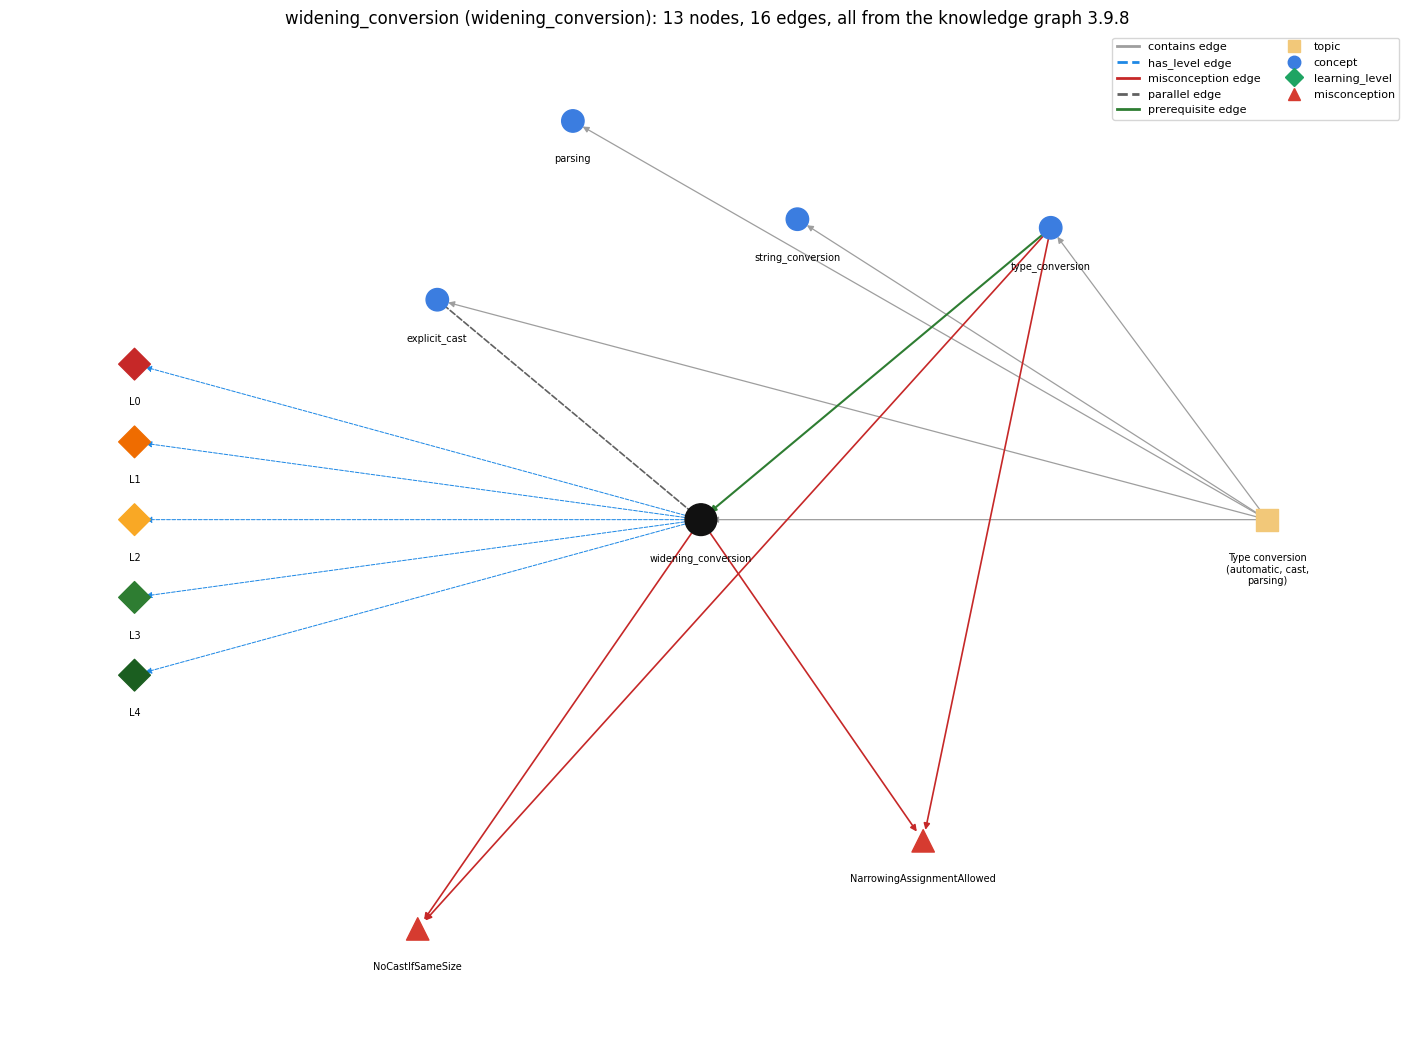

Rule type,Rule
E folk-meaning rule,"Folk meaning: like containers, a bigger box holds a smaller thing, and a smaller box holds a big thing if it happens to fit (3.0 fits in an int). Java rule: the compiler decides by types, not values: int to long or double is automatic, but double to int is never automatic, even for 3.0."
M wrong rule / right rule,"NarrowingAssignmentAllowed: wrong: A double value can be stored in an int variable like an int in a double. | right: int to double is automatic (widening); double to int needs a cast, otherwise the assignment is a compile-time error."
M wrong rule / right rule,"NoCastIfSameSize: wrong: If a variable is at least as big as a value, no cast is needed to assign the value. | right: The compiler decides by types, not values: assigning a double to an int needs a cast even when the value (e.g. 3.0) would fit, because a conversion that might involve loss of information leads to a compile-time error."
T uneven-application rule,"Points to LT (promotion happens at each operator, at the moment an int operand meets a double). Applied unevenly: the student promotes the whole expression up front on one line (so b*b - 4*c is done in double) but per operator on another."
N identity rule,"Widening conversion (promotion) is the automatic conversion of a value to a type with a larger range, e.g. int to long or double, char to int."
S declarative rule,"A value of a numeric type can be used wherever a type with a larger range is expected and is converted automatically; the magnitude is preserved (int to double is exact), though long to double may lose low-order precision."
LT operational sequencing rule,"At a binary operator, if one operand is double the other is widened to double just before that operation; in an assignment or method argument, the value is widened to the target type after it has been computed."
OP evaluation / result rule,The widened value has the larger type and the same magnitude: double d = 5; gives 5.0; 11 * 0.3 is double 3.3; 'a' + 1 is int 98; (x < 3.1) with int x = 3 is true.
OS state-transition rule,Widening creates the converted value for the target; the source variable keeps its type and value (after double d = n; n is still an int).
R composition rule (with a neighbour),with type_conversion: Widening is the automatic branch of type conversion; every other direction needs an explicit cast or method.


In [2]:
CONCEPT = 'widening_conversion'

# The view of one concept: every node the knowledge graph relates to it, and only edges that are in the graph.
import re
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

HERE = Path.cwd()                      # concept_wise_graph/<concept>/
VIEW_LAYERS = {'topic', 'concept', 'learning_level', 'misconception', 'error'}
VIEW_ETYPES = {'contains', 'prerequisite', 'parallel', 'has_level', 'misconception', 'error'}
HOPS = 1
hops_sl.value = HOPS

def _share_library(page):
    """The drawing library is the same in every page: one copy is kept one folder up."""
    def swap(m, name, tag):
        body = m.group(1)
        if len(body) < 100_000 or 'drawGraph' in body:      # the page's own script (its nodes and edges) stays
            return m.group(0)
        lib = HERE.parent / name
        if not lib.exists():
            lib.write_text(body, encoding='utf-8')
        return tag
    page = re.sub(r'<style[^>]*>(.*?)</style>',
                  lambda m: swap(m, 'vis-network.min.css', '<link rel="stylesheet" href="../vis-network.min.css">'),
                  page, flags=re.S)
    return re.sub(r'<script[^>]*>(.*?)</script>',
                  lambda m: swap(m, 'vis-network.min.js', '<script src="../vis-network.min.js"></script>'),
                  page, flags=re.S)

H, _ = filter_graph(VIEW_LAYERS, VIEW_ETYPES, 'All', '', HOPS, True, CONCEPT)
report, writeup = concept_report(CONCEPT), edges_writeup(H, CONCEPT)

# 1. the interactive page
page = _tips(_freeze(render(H, False, True, {CONCEPT}, CONCEPT, CONCEPT).generate_html(), False))
page = _share_library(page.replace('</body>', report + writeup + '</body>', 1))
(HERE / f'{CONCEPT}.html').write_text(page, encoding='utf-8')

# 2. the same view as data
(HERE / f'{CONCEPT}.json').write_text(json.dumps({
    'concept': CONCEPT, 'label': _CONCEPT[CONCEPT].get('label', CONCEPT), 'graph_version': DATA.get('version'),
    'nodes': [{'id': n, 'kind': d['layer'], 'label': d['label']}
              for n, d in sorted(H.nodes(data=True), key=lambda x: (x[1]['layer'], str(x[0])))],
    'edges': [{'from': u, 'to': v, 'type': d['etype'], 'label': d.get('elogic', '')}
              for u, v, d in sorted(H.edges(data=True), key=lambda x: (x[2]['etype'], str(x[0]), str(x[1])))],
}, indent=1, ensure_ascii=False), encoding='utf-8')

# 3. a still picture of the graph (same positions as the interactive page)
pos = {n: (x, -y) for n, (x, y) in radial_layout(H, CONCEPT).items()}
S = nx.DiGraph()
S.add_nodes_from(H.nodes())
fig, ax = plt.subplots(figsize=(18, 13))
keys = []
for et in sorted({d['etype'] for _, _, d in H.edges(data=True)}):
    st = EDGE_STYLE[et]
    nx.draw_networkx_edges(S, pos, ax=ax, edgelist=[(u, v) for u, v, d in H.edges(data=True) if d['etype'] == et],
                           edge_color=st['color'], width=st['width'] * 0.6, style='dashed' if st['dashes'] else 'solid',
                           arrows=True, arrowstyle='-' if et == 'parallel' else '-|>', arrowsize=9, node_size=260)
    keys.append(Line2D([], [], color=st['color'], lw=2, ls='--' if st['dashes'] else '-', label=et + ' edge'))
MARK = {'box': 's', 'dot': 'o', 'diamond': 'D', 'triangle': '^', 'star': '*'}
for lay, st in LAYER_STYLE.items():
    ns = [n for n, d in H.nodes(data=True) if d['layer'] == lay]
    if ns:
        cols = ([LEVEL_COLOR.get(H.nodes[n]['label'], st['color']) for n in ns] if lay == 'learning_level'
                else ['#111111' if n == CONCEPT else st['color'] for n in ns])
        nx.draw_networkx_nodes(S, pos, ax=ax, nodelist=ns, node_color=cols, node_shape=MARK[st['shape']],
                               node_size=[520 if n == CONCEPT else 260 for n in ns])
        keys.append(Line2D([], [], color=st['color'], marker=MARK[st['shape']], ls='', ms=9, label=lay))
nx.draw_networkx_labels(S, {n: (x, y - 55) for n, (x, y) in pos.items()}, ax=ax, font_size=7,
                        labels={n: _wrap(d['label'], 24) for n, d in H.nodes(data=True)}, verticalalignment='top')
ax.set_title(f"{_CONCEPT[CONCEPT].get('label', CONCEPT)} ({CONCEPT}): {H.number_of_nodes()} nodes, "
             f"{H.number_of_edges()} edges, all from the knowledge graph {str(DATA.get('version'))[:5]}")
ax.legend(handles=keys, loc='upper right', fontsize=8, ncol=2)
ax.margins(0.08)
ax.axis('off')
fig.savefig(HERE / f'{CONCEPT}.png', dpi=110, bbox_inches='tight')
plt.show()

# 4. the interactive graph, then the concept's report and every edge with its full label
rel = HERE.resolve().relative_to(ROOT).as_posix()
by = {}
for u, v, d in H.edges(data=True):
    by[d['etype']] = by.get(d['etype'], 0) + 1
display(HTML(
    f"<div style='background:#fff;color:#111;padding:8px;font-family:monospace'><b>{_esc(CONCEPT)}</b>: "
    f"{H.number_of_nodes()} nodes / {H.number_of_edges()} edges ("
    + ', '.join(f'{k} {n}' for k, n in sorted(by.items())) + "). Interactive graph: "
    f"<a href='/files/{rel}/{CONCEPT}.html' target='_blank'>{CONCEPT}.html</a> "
    "(shown below when the notebook server is running from the repository folder)</div>"
    f"<iframe src='/files/{rel}/{CONCEPT}.html' style='width:100%;height:1040px;border:1px solid #ddd;background:#fff'></iframe>"))
display(HTML(report + writeup))
